# D5 · From a VP metadata record to a notebook

This notebook starts from one thing only, the IRI of a dataset record in the ERDERA Virtual Platform, and follows the metadata to the data. Every URL it touches comes out of the record. Nothing else is typed in.

The chain is portal row → dataset record (FAIR Data Point) → distribution record → data file → first analysis → provenance record.

Today the portal's resource list shows these datasets without a link to their record, so the IRI below has to be taken from the VP Index or from the FDP that published the dataset (here the EJP RD WP13 FDP, `https://w3id.org/ejp-rd/fairdatapoints/wp13`). That gap is part of what this demonstrator shows.

In [1]:
# Parameters. DATASET_IRI is the dcat:Dataset IRI of the record to follow.
# Every URL the notebook fetches comes out of that record.
DATASET_IRI = "https://w3id.org/ejp-rd/fairdatapoints/wp13/dataset/22238845-1213-43f6-a60f-e84cdc9fa2ed"  # Huntingtons disease transcriptomics (GSE64810)
DOWNLOAD_DIR = "downloads"
OUTPUT_DIR = "output"

# How the downloaded file is laid out and which samples to compare. These describe the
# file's contents, not where it is. GSE64810 is one tab-separated matrix of DESeq2-normalised
# counts (gene x sample), and the sample names start with C_ (control) or H_ (Huntington).
DATA_SHEET = None                     # the sheet with the matrix, for a workbook
SAMPLE_SHEET = None                   # the sheet with one row per sample, if there is one
SAMPLE_ID_COLUMN = None
GROUP_COLUMN = None
GROUP_FROM_NAME = r"^([CH])_"         # regex whose first group is the label, when there is no sample sheet
CONTROL = r"^C$"                      # group labels matching this are the controls
CASE = "HD"                           # every other labelled sample
LOG_TRANSFORM = True                  # log2(x + 1) first, for count data

# EJPRD WP13 CAKUT mirnome instead: a workbook with a "Data matrix" sheet (miRNA x sample,
# RMA-normalised, already log scale) and a "Metadata" sheet, one row per sample.
# DATASET_IRI = "https://w3id.org/ejp-rd/fairdatapoints/wp13/dataset/0d2930d7-933d-4a5f-86e4-05e9537a18a0"
# DATA_SHEET, SAMPLE_SHEET = "Data matrix", "Metadata"
# SAMPLE_ID_COLUMN, GROUP_COLUMN, GROUP_FROM_NAME = "Sample name", "characteristics: group", None
# CONTROL, CASE, LOG_TRANSFORM = r"^Control", "CAKUT", False

assert DATASET_IRI, "Set DATASET_IRI to a dataset record IRI first."

In [2]:
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))   # the demonstrator folder, so that `src` imports
from src import firstlook, vpfollow

started = datetime.now(timezone.utc)

## 1. The dataset record

Fetch the record with content negotiation (an FDP serves Turtle) and read what it says about itself.

In [3]:
dataset, distributions = vpfollow.follow(DATASET_IRI)

print("Title      :", dataset.title)
print("Publisher  :", dataset.publisher_name or dataset.publisher_iri)
print("Licence    :", dataset.license)
print("Access     :", dataset.access_rights)
print("Themes     :", ", ".join(dataset.themes) or "(none)")
print("Keywords   :", ", ".join(dataset.keywords) or "(none)")
print("Landing    :", dataset.landing_page)
print("Distributions:", len(distributions))
print()
print(dataset.description)

Title      : Huntingtons disease transcriptomics
Publisher  : NCBI
Licence    : https://creativecommons.org/licenses/by-nc/4.0/
Access     : https://w3id.org/ejp-rd/fairdatapoints/wp13/dataset/22238845-1213-43f6-a60f-e84cdc9fa2ed#accessRights
Themes     : http://edamontology.org/topic_3170, http://edamontology.org/topic_3308, http://www.orpha.net/ORDO/Orphanet_399
Keywords   : RNA-Seq, huntington's disease, transcriptomics
Landing    : None
Distributions: 2

Huntingtons disease RNA-Seq transcriptomics dataset


## 2. The distributions

Each distribution is its own record. We follow the one we can download.

In [4]:
pd.DataFrame([{
    "title": d.title,
    "media type": d.media_type,
    "download URL": d.download_url,
    "access URL": d.access_url,
    "licence": d.license,
} for d in distributions])

,title,media type,download URL,access URL,licence
0,Access distribution of : Distribution of Hunti...,text/csv,NaN,https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi...,https://creativecommons.org/licenses/by-nc/4.0
1,Downloadable distribution of : Distribution of...,text/csv,https://www.ncbi.nlm.nih.gov/geo/download/?acc...,NaN,https://creativecommons.org/licenses/by-nc/4.0


In [5]:
chosen = vpfollow.choose(distributions)
assert chosen is not None, "No distribution carries a download or access URL; see the README fallback."
print("Following:", chosen.title)
print("URL      :", chosen.data_url)

downloaded = vpfollow.download(chosen.data_url, DOWNLOAD_DIR)
print("Saved to :", downloaded, f"({downloaded.stat().st_size:,} bytes)")

Following: Downloadable distribution of : Distribution of Huntington disease transcriptomics
URL      : https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE64810&format=file&file=GSE64810%255Fmlhd%255FDESeq2%255Fnorm%255Fcounts%255Fadjust%252Etxt%252Egz


Saved to : downloads/GSE64810_mlhd_DESeq2_norm_counts_adjust.txt (30,463,034 bytes)


## 3. The data

Load the file and look at it. A workbook says what is inside it, so list its sheets first. The analysis below is deliberately simple, a case-versus-control difference of means per feature. The point is that we got here from the metadata alone.

In [6]:
print("Sheets:", vpfollow.sheets(downloaded) or "(text file)")
table = vpfollow.load_table(downloaded, sheet=DATA_SHEET)
matrix = firstlook.as_matrix(table)
if LOG_TRANSFORM:
    matrix = np.log2(matrix + 1)
print(f"{matrix.shape[0]:,} features x {matrix.shape[1]} samples")
matrix.iloc[:5, :6]

Sheets: (text file)
28,087 features x 69 samples


,C_0002,C_0003,C_0004,C_0005,C_0006,C_0008
feature,,,,,,
ENSG00000000003.10,8.324165,8.268356,8.021849,7.869915,7.845828,8.186928
ENSG00000000005.5,0.000000,1.576671,2.989839,1.576454,1.990855,3.158563
ENSG00000000419.8,9.231932,9.157492,9.226805,9.309166,8.785483,9.360096
ENSG00000000457.8,7.310738,7.405471,7.519826,7.579741,7.617212,7.623901
ENSG00000000460.12,7.255600,7.300507,7.207628,6.768694,7.117164,7.309220


In [7]:
if SAMPLE_SHEET:
    sample_sheet = vpfollow.load_table(downloaded, sheet=SAMPLE_SHEET)
    labels = firstlook.groups_from_sheet(sample_sheet, SAMPLE_ID_COLUMN, GROUP_COLUMN)
else:
    labels = firstlook.groups_from_names(matrix.columns, GROUP_FROM_NAME)
groups = firstlook.two_groups(labels, CONTROL, CASE)

print(labels.value_counts().to_string(), end="\n\n")
print(groups.value_counts().to_string())

group
C    49
H    20

group
control    49
HD         20


In [8]:
summary = firstlook.compare(matrix, groups)
case = summary.attrs["case"]
print("Samples compared:", summary.attrs["n"])
summary.head(20)

Samples compared: {'control': 49, 'HD': 20}


,HD,control,difference
feature,,,
ENSG00000069011.10,4.088994,0.238695,3.850299
ENSG00000152779.12,6.135702,2.521319,3.614382
ENSG00000163221.7,4.885145,1.574687,3.310458
ENSG00000112499.7,4.381213,1.080442,3.300772
ENSG00000106809.6,8.366147,5.125165,3.240981
ENSG00000115590.9,4.486399,1.310785,3.175614
ENSG00000115602.12,7.836965,4.754286,3.082679
ENSG00000112175.6,5.564031,2.542693,3.021338
ENSG00000143546.5,7.976429,4.972617,3.003812


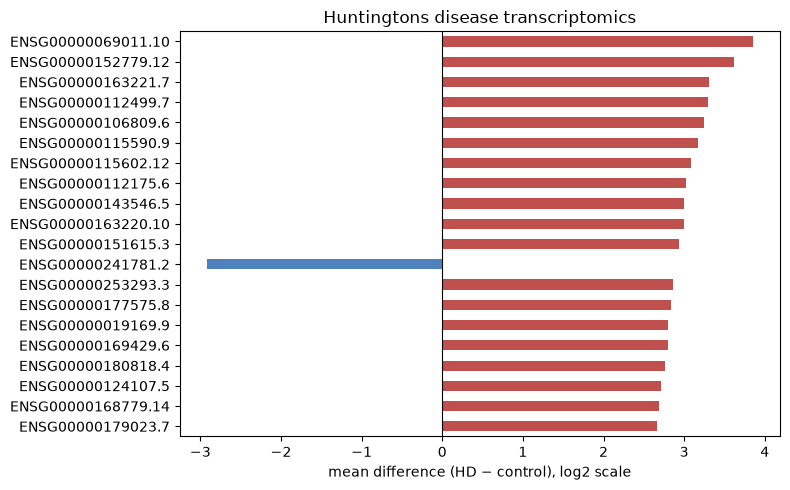

In [9]:
top = summary.head(20)
fig, ax = plt.subplots(figsize=(8, 5))
top["difference"].plot.barh(ax=ax, color=np.where(top["difference"] > 0, "#c0504d", "#4f81bd"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel(f"mean difference ({case} − control), log2 scale")
ax.set_ylabel("")
ax.set_title(dataset.title or DATASET_IRI)
ax.invert_yaxis()
plt.tight_layout()

Path(OUTPUT_DIR).mkdir(exist_ok=True)
figure_path = Path(OUTPUT_DIR) / "top_differences.png"
fig.savefig(figure_path, dpi=150)

## 4. Provenance

A small PROV-O record of what this run fetched and produced, so the analysis itself is traceable.

In [10]:
prov = vpfollow.prov_graph(dataset, chosen, downloaded, started)
prov_path = Path(OUTPUT_DIR) / "prov.ttl"
prov.serialize(destination=str(prov_path), format="turtle")
print(prov_path.read_text())

@prefix dct: <http://purl.org/dc/terms/> .
@prefix prov: <http://www.w3.org/ns/prov#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<https://github.com/luizbonino/erdera-demonstrators/tree/main/demonstrators/D05-metadata-to-notebook#run-20261106T122808Z/GSE64810_mlhd_DESeq2_norm_counts_adjust.txt> a prov:Entity ;
    rdfs:label "GSE64810_mlhd_DESeq2_norm_counts_adjust.txt" ;
    prov:wasDerivedFrom <https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE64810&format=file&file=GSE64810%255Fmlhd%255FDESeq2%255Fnorm%255Fcounts%255Fadjust%252Etxt%252Egz> ;
    prov:wasGeneratedBy <https://github.com/luizbonino/erdera-demonstrators/tree/main/demonstrators/D05-metadata-to-notebook#run-20261106T122808Z> .

<https://github.com/luizbonino/erdera-demonstrators/tree/main/demonstrators/D05-metadata-to-notebook> a prov:SoftwareAgent .

<https://github.com/luizbonino/erdera-demonstrators/tree/main/demonstrators/D05-metadata-to-notebook#run-2

## What this shows

- A dataset in the VP can be reached and used from its metadata alone, with the licence and publisher the record states known before any data is downloaded.
- The record is only as good as what was entered. The Huntington record names NCBI as publisher under an IRI that is a file path left by the script that populated the FDP, and calls a gzipped tab-separated file `text/csv`. For the WP13 CAKUT datasets the record's licence (CC BY-NC-ND 3.0) differs from the repository's (CC BY 4.0 on Zenodo). See `records.md`.
- The portal's resource list does not yet link to the record, so a user has to know the IRI. Closing that gap is a portal change worth requesting.
- The notebook itself can be registered as a resource in the demo index with FDPlight, which is the second act of this demonstrator.